# Day 08. Exercise 03
# Overfitting

## 0. Imports

In [289]:
import pandas as pd
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

from sklearn.model_selection import cross_val_score
from sklearn.multiclass import OneVsRestClassifier

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

import joblib
import matplotlib.pyplot as plt

## 1. Preprocessing

1. Read the file `dayofweek.csv` to a dataframe.
2. Using `train_test_split` with parameters `test_size=0.2`, `random_state=21` get `X_train`, `y_train`, `X_test`, `y_test`.
3. Using, for example, `value_counts()` to check if the distribution of classes is similar in train and test.
4. Use the additional parameter `stratify=` and check the distribution again, now it should be more or less similar in both datasets.

In [290]:
df = pd.read_csv('../data/dayofweek.csv')
X = df.drop('dayofweek', axis=1)
y = df['dayofweek']

In [291]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21)

In [292]:
dist_train = y_train.value_counts(normalize=True).sort_index()
dist_test = y_test.value_counts(normalize=True).sort_index()

In [293]:
comparison = pd.DataFrame({'Train %': dist_train, 'Test %': dist_test})
comparison

,Train %,Test %
dayofweek,,
0,0.077893,0.091716
1,0.164688,0.153846
2,0.092730,0.071006
3,0.232196,0.245562
4,0.059347,0.071006
5,0.160237,0.162722
6,0.212908,0.204142


In [294]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=21, stratify=y)

In [295]:
dist_train_strat = y_train.value_counts(normalize=True).sort_index()
dist_test_strat = y_test.value_counts(normalize=True).sort_index()

In [296]:
comparison_strat = pd.DataFrame({'Train %': dist_train_strat, 'Test %': dist_test_strat})
comparison_strat

,Train %,Test %
dayofweek,,
0,0.080861,0.079882
1,0.162463,0.162722
2,0.088279,0.088757
3,0.234421,0.236686
4,0.061573,0.062130
5,0.160979,0.159763
6,0.211424,0.210059


## 2. Baseline models

1. Train exactly the same baseline models from the previous exercise and calculate the accuracies using the test dataset with stratification.
2. Did all the models show the similar values of the metric? Which one has the largest difference comparing the current exercise and the previous? Put the answer to the markdown cell in the end of the section.

In [297]:
test_accuracies = {}

### a. Logreg

In [298]:
lr = LogisticRegression(random_state=21, fit_intercept=False, max_iter=1000)
lr.fit(X_train, y_train)
test_accuracies['Logistic Regression'] = accuracy_score(y_test, lr.predict(X_test))

### b. SVM

In [299]:
svc = OneVsRestClassifier(SVC(kernel='linear', probability=True, random_state=21))
svc.fit(X_train, y_train)
test_accuracies['SVC'] = accuracy_score(y_test, svc.predict(X_test))

### c. Decision tree

In [300]:
dt = DecisionTreeClassifier(max_depth=4, random_state=21)
dt.fit(X_train, y_train)
test_accuracies['Decision Tree'] = accuracy_score(y_test, dt.predict(X_test))

### d. Random forest

In [301]:
rf = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
rf.fit(X_train, y_train)
test_accuracies['Random Forest'] = accuracy_score(y_test, rf.predict(X_test))

In [302]:
for model, acc in test_accuracies.items():
    print(f"{model}: accuracy = {acc}")

Logistic Regression: accuracy = 0.6331360946745562
SVC: accuracy = 0.6183431952662722
Decision Tree: accuracy = 0.5295857988165681
Random Forest: accuracy = 0.9319526627218935


no, random forest in our test dropped the accuracy from 99.8 to 93

## 3. Crossvalidation

We could play with parameters of the model trying to achive a better accuracy on the test dataset, but it is a bad practice. It leads us again to overfitting. Test dataset is only for checking quality of a final model.

But there is another way of solving the problem – crossvalidation. It does not use test dataset, but creates one more split of train dataset. Again, there are different ways of doing it, but the common thing is that there is a validation dataset that is used for hyperparameters optimization.

1. Using `cross_val_score` with `cv=10` calculate the mean accuracy and standard deviation for every model that you used before (logreg with `solver='liblinear'`, SVC, decision tree, random forest).

### a. Logreg

In [303]:
lr_base = LogisticRegression(solver='liblinear', random_state=21, fit_intercept=False)
lr = OneVsRestClassifier(lr_base)

scores_lr = cross_val_score(lr, X_train, y_train, cv=10)

In [304]:
scores_lr.mean()

np.float64(0.5815975677169707)

In [305]:
scores_lr.std()

np.float64(0.025322132907253592)

### b. SVM

In [306]:
svc = SVC(kernel='linear', probability=True, random_state=21)
scores_svc = cross_val_score(svc, X_train, y_train, cv=10)

In [307]:
scores_svc.mean()

np.float64(0.6587064676616916)

In [308]:
scores_svc.std()

np.float64(0.043585708770590564)

### c. Decision tree

In [309]:
dt = DecisionTreeClassifier(max_depth=4, random_state=21)
scores_dt = cross_val_score(dt, X_train, y_train, cv=10)

In [310]:
scores_dt.mean()

np.float64(0.5088944168048645)

In [311]:
scores_dt.std()

np.float64(0.031903139495514356)

### d. Random forest

In [312]:
rf = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
scores_rf = cross_val_score(rf, X_train, y_train, cv=10)

In [313]:
scores_rf.mean()

np.float64(0.9117191818684356)

In [314]:
scores_rf.std()

np.float64(0.017368532539708048)

## 4. Optimization

1. Choose the best model and play a little bit with the parameters on cross-validation, find a good enough parameter or a combination of the parameters.
2. Calculate the accuracy for the final model on the test dataset.
3. Draw a plot that displays the top-10 most  important features for that model.
4. Save the model using `joblib`.
5. Load the model, make predictions for the test dataset and calculate the accuracy.

In [315]:
final_model = RandomForestClassifier(n_estimators=200, max_depth=25, random_state=21)
final_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",25
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y

In [316]:
test_preds = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, test_preds)

In [317]:
final_accuracy

0.9319526627218935

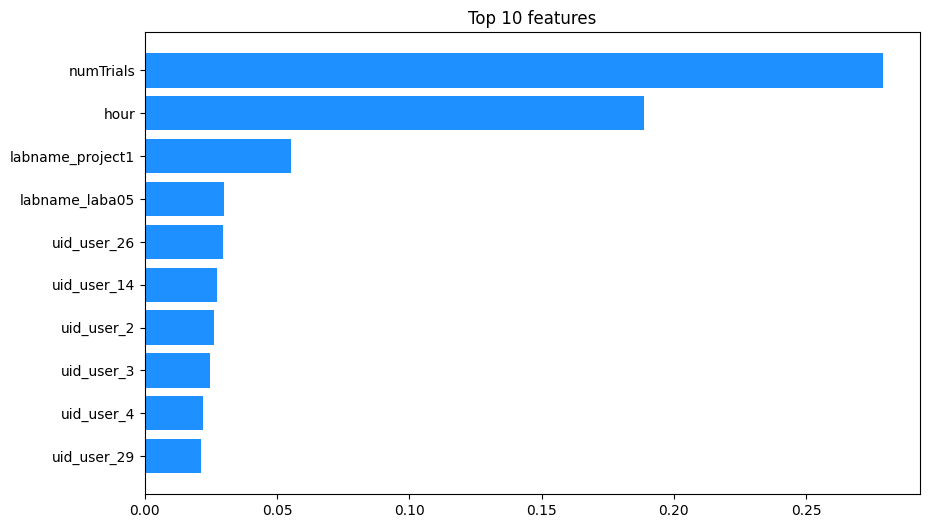

In [318]:
def plot_final_importance(model, feature_names, n_top=10):
    importances = model.feature_importances_
    feat_importance = pd.DataFrame({'feature': feature_names, 'importance': importances})
    feat_importance = feat_importance.sort_values('importance', ascending=False).head(n_top)
    
    plt.figure(figsize=(10, 6))
    plt.barh(feat_importance['feature'], feat_importance['importance'], color='dodgerblue')
    plt.gca().invert_yaxis()
    plt.title(f"Top {n_top} features")
    plt.show()

plot_final_importance(final_model, X.columns)

In [319]:
joblib.dump(final_model, '../data/final_model.joblib')


['../data/final_model.joblib']

In [320]:
loaded_model = joblib.load('../data/final_model.joblib')
loaded_preds = loaded_model.predict(X_test)
loaded_accuracy = accuracy_score(y_test, loaded_preds)

In [321]:
loaded_accuracy

0.9319526627218935

In [322]:
final_accuracy == loaded_accuracy

True